In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 7 (1.2 MB)
Directories removed: 5


In [2]:
!cd ../.. && pip install -v . --group=dev --group=observability --group=sandbox

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 20.5 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 

# Basic overview of finished case x scenario runs

In [3]:
from pathlib import Path

EXPERIMENT_BASE_DIR = "../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [4]:
import pandas as pd

In [5]:
experiment_log = pd.read_csv("../runtime/experiment_cross_scenarios_cases.log.csv")

In [6]:
experiment_log.describe(include="all")

,Unnamed: 0_x,variant,schema,strategy,provider,config,scenario_id,scenario_tag,Unnamed: 0.4,Unnamed: 0.3,...,ground_truth_metadata_dir,ground_truth_metadata_eml,ground_truth_metadata_dwc,case_id,scenario_x_case_tag,short_scenario_x_case_tag,success,outcome_json,duration_ms,timestamp
count,358.000000,358,358,358,358,358,358.000000,358,358.000000,358.000000,...,358,358,358,358.000000,358,358,358,358,358.000000,3.580000e+02
unique,NaN,1,1,2,1,1,NaN,2,NaN,NaN,...,179,179,179,NaN,358,358,2,358,NaN,NaN
top,NaN,full,dwc,data-focus,openai-platform,"{'provider': 'openai-platform', 'core_platform...",NaN,s_0--full-dwc-data-focus-openai-platform-{'pro...,NaN,NaN,...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...,NaN,c_0-x-s_0--full-dwc-data-focus-openai-platform...,c_0-x-s_0,True,"{""messages"": [], ""settings"": {""runtime_config""...",NaN,NaN
freq,NaN,358,358,179,358,358,NaN,179,NaN,NaN,...,2,2,2,NaN,1,1,354,1,NaN,NaN
mean,2.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,89.000000,105.424581,...,NaN,NaN,NaN,89.000000,NaN,NaN,NaN,NaN,43.964562,1.778160e+09
std,2.002799,NaN,NaN,NaN,NaN,NaN,2.002799,NaN,51.744362,62.982979,...,NaN,NaN,NaN,51.744362,NaN,NaN,NaN,NaN,67.038900,5.614363e+03
min,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,...,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,12.870421,1.778149e+09
25%,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,44.250000,53.250000,...,NaN,NaN,NaN,44.250000,NaN,NaN,NaN,NaN,23.320225,1.778155e+09
50%,2.000000,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,89.000000,100.000000,...,NaN,NaN,NaN,89.000000,NaN,NaN,NaN,NaN,29.686688,1.778160e+09
75%,4.000000,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,133.750000,161.750000,...,NaN,NaN,NaN,133.750000,NaN,NaN,NaN,NaN,42.349698,1.778165e+09


In [7]:
experiment_log.columns

Index(['Unnamed: 0_x', 'variant', 'schema', 'strategy', 'provider', 'config',
       'scenario_id', 'scenario_tag', 'Unnamed: 0.4', 'Unnamed: 0.3',
       'Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0_y', 'title', 'authors',
       'source', 'published', 'open_access', 'peer_review', 'citation_type',
       'countries_of_coverage', 'countries_of_researcher', 'keywords',
       'literature_type', 'websites', 'identifiers', 'id', 'abstract',
       'topics', 'added', 'gbif_download_key', 'literature_metadata',
       'gbif_data_id_data', 'dataset_metadata', 'dwca_url', 'data_standard',
       'doi_url', 'genre', 'has_repository_copy', 'is_oa', 'is_paratext',
       'journal_is_in_doaj', 'journal_is_oa', 'journal_issn_l',
       'journal_issns', 'journal_name', 'oa_locations',
       'oa_locations_embargoed', 'oa_status', 'published_date', 'publisher',
       'title_unp', 'updated', 'year', 'z_authors',
       'best_oa_location.endpoint_id', 'best_oa_location.evidence',
       'best_oa_loca

In [8]:
experiment_log["out_dir"] = experiment_log["short_scenario_x_case_tag"].apply(lambda t: f"out/{t}")

In [9]:
experiment_log[["out_dir","working_copy_data_dir","ground_truth_metadata_dwc"]]

,out_dir,working_copy_data_dir,ground_truth_metadata_dwc
0,out/c_0-x-s_0,working_copy/data/000-6f97bcef-7324-3425-bb72-...,ground_truth/data/000-6f97bcef-7324-3425-bb72-...
1,out/c_1-x-s_0,working_copy/data/001-2fee34a0-a302-3c12-8916-...,ground_truth/data/001-2fee34a0-a302-3c12-8916-...
2,out/c_2-x-s_0,working_copy/data/002-325b19cf-6c16-3147-b8db-...,ground_truth/data/002-325b19cf-6c16-3147-b8db-...
3,out/c_3-x-s_0,working_copy/data/003-d72b6b4f-0fb1-301e-81d0-...,ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...
4,out/c_4-x-s_0,working_copy/data/004-93ed8a30-2f05-37c7-a371-...,ground_truth/data/004-93ed8a30-2f05-37c7-a371-...
...,...,...,...
353,out/c_174-x-s_4,working_copy/data/208-8395f577-f4ec-3cc9-9d46-...,ground_truth/data/208-8395f577-f4ec-3cc9-9d46-...
354,out/c_175-x-s_4,working_copy/data/209-1cf45154-9800-31c6-ba38-...,ground_truth/data/209-1cf45154-9800-31c6-ba38-...
355,out/c_176-x-s_4,working_copy/data/210-99ee49cb-8bcd-39a4-895b-...,ground_truth/data/210-99ee49cb-8bcd-39a4-895b-...
356,out/c_177-x-s_4,working_copy/data/211-5ef32ca0-b247-30f8-aed8-...,ground_truth/data/211-5ef32ca0-b247-30f8-aed8-...


In [10]:
experiment_log.to_csv("../runtime/__experiment_cross_scenarios_cases.log.csv")

## EDA

In [11]:
import matplotlib.pyplot as plt

In [12]:
plt.rcParams["figure.dpi"] = 140

> _Total number of experiments per strategy and schema_

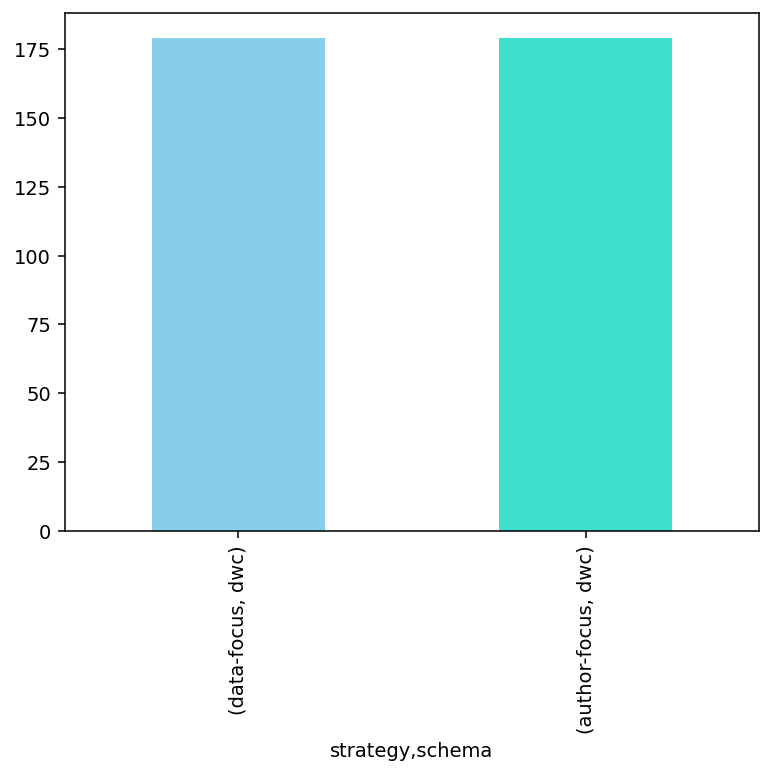

In [13]:
_ = experiment_log[['strategy', 'schema']].value_counts().plot(kind='bar', color=['skyblue', 'turquoise'])

> _Number of success and failures of experiments per strategy and schema_

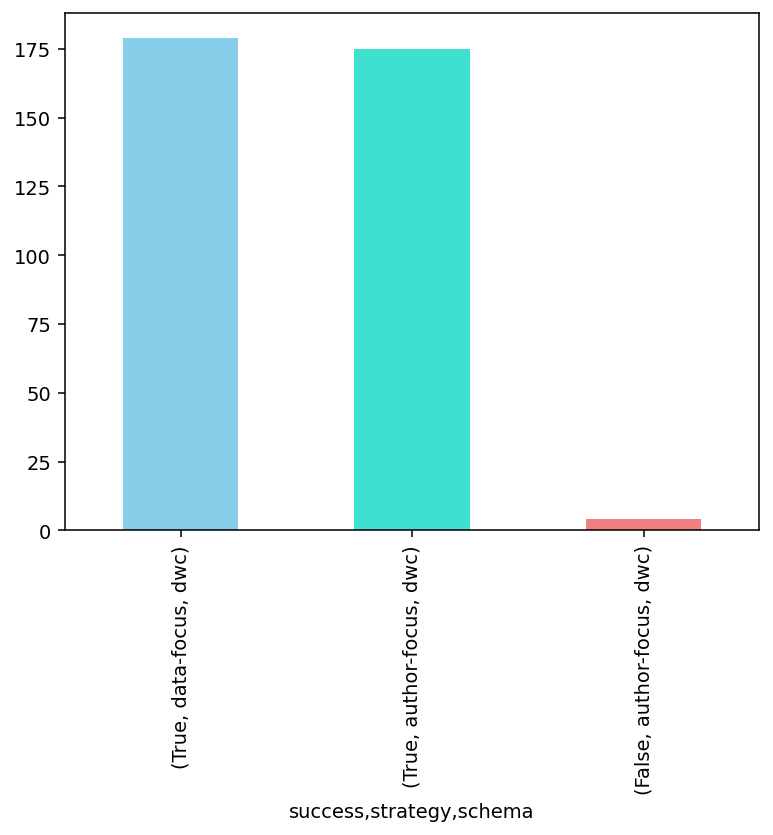

In [14]:
_ = experiment_log[['success', 'strategy', 'schema']].value_counts().plot(
    kind='bar', 
    color=['skyblue', 'turquoise', 'lightcoral', 'salmon']
)

> _Duration histogram (in minutes)_

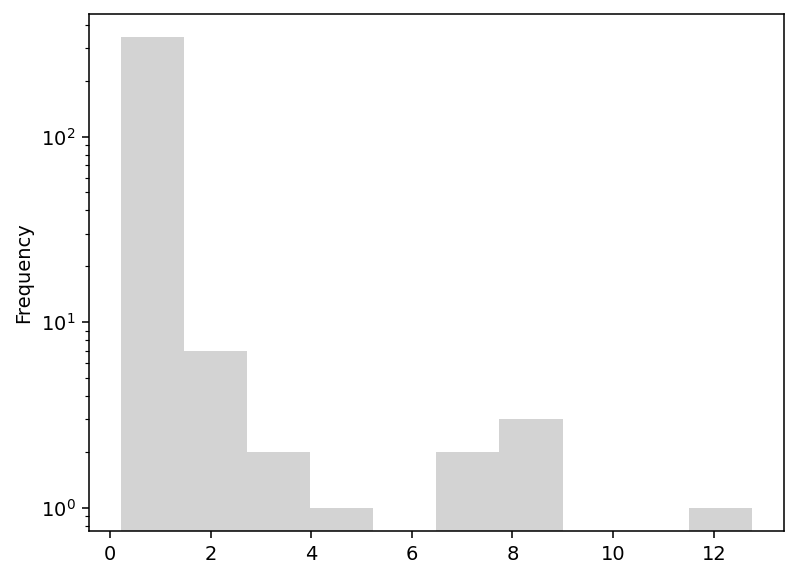

In [15]:
ax = (experiment_log["duration_ms"] / 60).plot.hist(log=True, color="lightgray")

In [16]:
experiment_log["duration_minutes"] = (experiment_log["duration_ms"] / 60)

> _Duration histogram of succeeded experiments (minutes)_

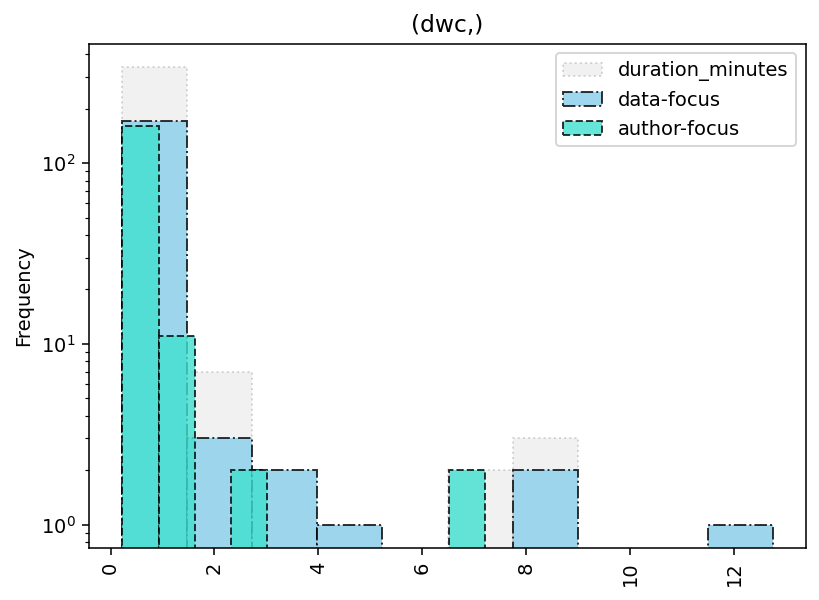

In [17]:
ax = (experiment_log["duration_minutes"]).plot.hist(log=True, color="lightgray", alpha=0.3, legend=True, ls=":", edgecolor="grey")
_ = experiment_log[(experiment_log["success"] == True) & (experiment_log["strategy"] == "data-focus")].hist(
    column='duration_minutes', 
    by=['schema'], 
    color=["skyblue"],
    sharey=True,
    log=True,
    alpha=0.8,
    edgecolor="black",
    ls="-.",
    label="data-focus",
    ax=ax
)
_ = experiment_log[(experiment_log["success"] == True) & (experiment_log["strategy"] == "author-focus")].hist(
    column='duration_minutes', 
    by=['schema'], 
    color=["turquoise"],
    sharey=True,
    log=True,
    alpha=0.8,
    edgecolor="black",
    ls="--",
    label="author-focus",
    ax=ax
)
_ = ax.legend()

> _Duration histogram of failed experiments (minutes)_

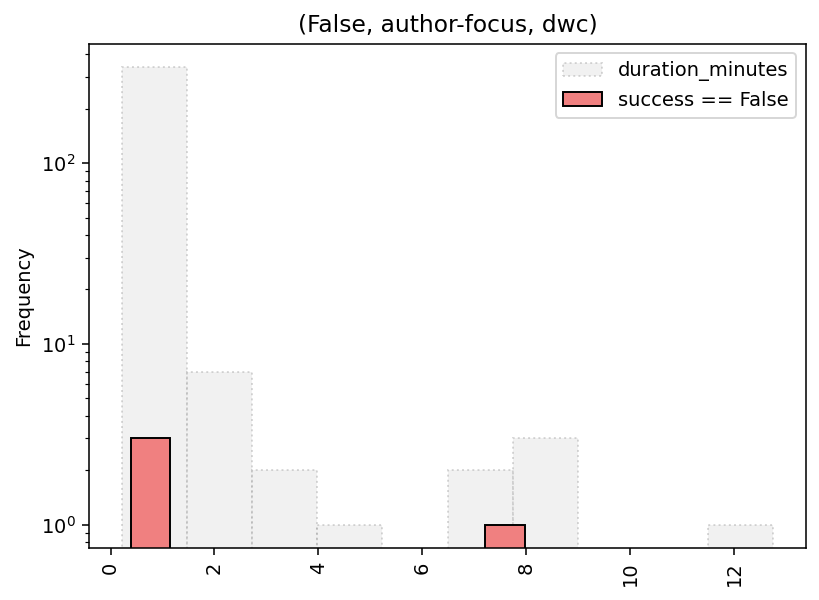

In [18]:
ax = (experiment_log["duration_minutes"]).plot.hist(log=True, color="lightgray", alpha=0.3, legend=True, ls=":", edgecolor="grey")
_ = experiment_log[experiment_log["success"] == False].hist(
    column='duration_minutes', 
    by=['success', 'strategy', 'schema'], 
    color=["lightcoral"],
    sharey=True,
    log=True,
    edgecolor="black",
    label="success == False",
    ax=ax
)
_ = ax.legend()

> _Example successful metadata_

In [19]:
first_experiment_metadata = next(experiment_log[["out_dir","working_copy_data_dir","ground_truth_metadata_dwc", "outcome_json"]].head(1).iterrows())

In [20]:
entries = first_experiment_metadata[1].tolist()
first_out_dir, first_working_copy_data, first_gt_metadata, first_outcome_json = list(map(grounded_path, entries[:3])) + [entries[3]]

In [21]:
list(first_working_copy_data.iterdir())

[PosixPath('../../_data/gbif_data_archive/working_copy/data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data/event.txt'),
 PosixPath('../../_data/gbif_data_archive/working_copy/data/000-6f97bcef-7324-3425-bb72-0dc035031776-download-data/occurrence.txt')]

> _Produced `meta.xml`_

In [22]:
import json

In [23]:
first_outcome = json.loads(first_outcome_json)

In [24]:
first_outcome_meta_xml = first_outcome["resolutions"][0]["working_copy_xml_blueprint"]["content"]
print(first_outcome_meta_xml)

<?xml version="1.0" encoding="UTF-8"?>
<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="meta.xml">
  <core rowType="http://rs.tdwg.org/dwc/terms/Occurrence" fieldsTerminatedBy="\t" fieldsEnclosedBy="&quot;" ignoreHeaderLines="1" encoding="UTF-8">
    <files>
      <location>occurrence.txt</location>
    </files>
    <id index="0" />
    <field index="1" term="http://rs.tdwg.org/dwc/terms/type" />
    <field index="2" term="http://rs.tdwg.org/dwc/terms/license" />
    <field index="3" term="http://rs.tdwg.org/dwc/terms/institutionID" />
    <field index="4" term="http://rs.tdwg.org/dwc/terms/collectionID" />
    <field index="5" term="http://rs.tdwg.org/dwc/terms/institutionCode" />
    <field index="6" term="http://rs.tdwg.org/dwc/terms/collectionCode" />
    <field index="7" term="http://rs.tdwg.org/dwc/terms/datasetName" />
    <field index="8" term="http://rs.tdwg.org/dwc/terms/basisOfRecord" />
    <field index="9" term="http://rs.tdwg.org/dwc/terms/occurrenceID" />
    <fie

> _Ground truth `meta.xml`_

In [25]:
first_gt_metadata_xml = first_gt_metadata.read_text()
print(first_gt_metadata_xml)

<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="eml.xml">
  <core encoding="UTF-8" fieldsTerminatedBy="\t" linesTerminatedBy="\n" fieldsEnclosedBy="" ignoreHeaderLines="1" rowType="http://rs.tdwg.org/dwc/terms/Event">
    <files>
      <location>event.txt</location>
    </files>
    <id index="0" />
    <field index="1" term="http://rs.tdwg.org/dwc/terms/eventID"/>
    <field index="2" term="http://rs.tdwg.org/dwc/terms/eventDate"/>
    <field index="3" term="http://rs.tdwg.org/dwc/terms/year"/>
    <field index="4" term="http://rs.tdwg.org/dwc/terms/month"/>
    <field index="5" term="http://rs.tdwg.org/dwc/terms/day"/>
    <field index="6" term="http://rs.tdwg.org/dwc/terms/habitat"/>
    <field index="7" term="http://rs.tdwg.org/dwc/terms/samplingProtocol"/>
    <field index="8" term="http://rs.tdwg.org/dwc/terms/sampleSizeValue"/>
    <field index="9" term="http://rs.tdwg.org/dwc/terms/sampleSizeUnit"/>
    <field index="10" term="http://rs.tdwg.org/dwc/terms/samplingEffort

In [26]:
from xmldiff import main

> _Quick overview of diffs_

In [27]:
main.diff_texts("\n".join(first_outcome_meta_xml.split("\n")[1:]), first_gt_metadata_xml)

[UpdateAttrib(node='/*[1]', name='metadata', value='eml.xml'),
 MoveNode(node='/*/*[1]', target='/*[1]', position=1),
 RenameNode(node='/*/*[1]', tag='{http://rs.tdwg.org/dwc/text/}core'),
 UpdateAttrib(node='/*/*[1]', name='fieldsEnclosedBy', value=''),
 InsertAttrib(node='/*/*[1]', name='linesTerminatedBy', value='\\n'),
 MoveNode(node='/*/*[1]/*[5]', target='/*/*[1]', position=14),
 MoveNode(node='/*/*[1]/*[5]', target='/*/*[1]', position=5),
 MoveNode(node='/*/*[1]/*[7]', target='/*/*[1]', position=14),
 MoveNode(node='/*/*[1]/*[18]', target='/*/*[1]', position=15),
 MoveNode(node='/*/*[1]/*[19]', target='/*/*[1]', position=19),
 MoveNode(node='/*/*[1]/*[22]', target='/*/*[1]', position=18),
 MoveNode(node='/*/*[1]/*[23]', target='/*/*[1]', position=26),
 MoveNode(node='/*/*[1]/*[25]', target='/*/*[1]', position=26),
 RenameNode(node='/*/*[2]', tag='{http://rs.tdwg.org/dwc/text/}extension'),
 UpdateAttrib(node='/*/*[2]', name='fieldsEnclosedBy', value=''),
 InsertAttrib(node='/*/*[